In [2]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

BASE_PATH   = '/Users/milliespencer/Desktop/CR2_OGGM_Paper'
CAMELS_FULL = f'{BASE_PATH}/Full_CAMELS_all_basins/CAMELS_CL_v202201'
BOUNDS_PATH = f'{CAMELS_FULL}/camels_cl_boundaries/camels_cl_boundaries.shp'
NESTED_CSV_PATH = f'{BASE_PATH}/Output/all_chile_results_v2/spatial_join_nested.csv'
HYBAS_PATH  = f'{BASE_PATH}/november_tinker/hybas_sa_lev09_v1c/hybas_sa_lev09_v1c.shp'
CARO_CSV    = f'{BASE_PATH}/november_tinker/Glacio_hydro_summary_per_catchment_2000_2019.csv'

AREA_CRS    = 'ESRI:102033'   # South America Albers equal area, for areas
CONTAIN_MIN = 0.9             # a Caro catchment is "inside" a CAMELS polygon if >= this fraction is
UNIT_IDS    = None            # optional: list of gauge_ids (e.g. the 48 units) to restrict CAMELS

for p in [BOUNDS_PATH, NESTED_CSV_PATH, HYBAS_PATH, CARO_CSV]:
    print(f'{os.path.exists(p)}  {p}')

bounds_all = gpd.read_file(BOUNDS_PATH).to_crs(epsg=4326)
bounds_all['gauge_id'] = bounds_all['gauge_id'].astype(str)

nested_csv = pd.read_csv(NESTED_CSV_PATH, dtype={'gauge_id': str})
glacier_area_by_gauge = nested_csv.groupby('gauge_id')['Area'].sum().to_dict()
glacierized = {g for g, a in glacier_area_by_gauge.items() if a > 0}

camels = bounds_all[bounds_all['gauge_id'].isin(glacierized)]
if UNIT_IDS is not None:
    camels = camels[camels['gauge_id'].isin([str(u) for u in UNIT_IDS])]

hyb  = gpd.read_file(HYBAS_PATH)
caro = pd.read_csv(CARO_CSV)

hit = caro['id_basin'].isin(hyb['HYBAS_ID'])
print(f'\nCAMELS polygons used (glacierized): {len(camels)} of {len(bounds_all)}')
print(f'Caro catchments: {len(caro)} | found in HydroBASINS lvl 9: {hit.sum()} | missing: {(~hit).sum()}')

True  /Users/milliespencer/Desktop/CR2_OGGM_Paper/Full_CAMELS_all_basins/CAMELS_CL_v202201/camels_cl_boundaries/camels_cl_boundaries.shp
True  /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/all_chile_results_v2/spatial_join_nested.csv
True  /Users/milliespencer/Desktop/CR2_OGGM_Paper/november_tinker/hybas_sa_lev09_v1c/hybas_sa_lev09_v1c.shp
True  /Users/milliespencer/Desktop/CR2_OGGM_Paper/november_tinker/Glacio_hydro_summary_per_catchment_2000_2019.csv

CAMELS polygons used (glacierized): 266 of 516
Caro catchments: 786 | found in HydroBASINS lvl 9: 786 | missing: 0


overlay and summary: 

In [9]:
cg = hyb.merge(caro, left_on='HYBAS_ID', right_on='id_basin', how='inner').to_crs(AREA_CRS)
cm = camels.to_crs(AREA_CRS)
cg['area_km2_poly'] = cg.geometry.area / 1e6
cm['area_km2_poly'] = cm.geometry.area / 1e6

# ---- Chile flag (representative point, so border catchments aren't split) ----
world = gpd.read_file('https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip')
chile_geom = world[world['NAME'] == 'Chile'].to_crs(AREA_CRS).geometry.unary_union
pts = cg.copy()
pts['geometry'] = cg.geometry.representative_point()
cg['in_chile'] = pts.geometry.within(chile_geom).values

# fraction of each Caro catchment inside each CAMELS polygon (all 786, before any clipping)
ov = gpd.overlay(cg[['id_basin', 'geometry']], cm[['gauge_id', 'geometry']], how='intersection')
ov['frac_in'] = (ov.geometry.area / 1e6) / ov['id_basin'].map(cg.set_index('id_basin')['area_km2_poly'])
inside = ov[ov['frac_in'] >= CONTAIN_MIN][['id_basin', 'gauge_id', 'frac_in']]

# keep: in Chile, OR inside one of our polygons (transboundary basins include the Argentine side)
cg['in_camels'] = cg['id_basin'].isin(inside['id_basin'])
cg['keep'] = cg['in_chile'] | cg['in_camels']
print(f'Caro catchments: {len(cg)} | in Chile: {cg["in_chile"].sum()} | '
      f'outside Chile but inside a CAMELS polygon: {(~cg["in_chile"] & cg["in_camels"]).sum()} | '
      f'dropped: {(~cg["keep"]).sum()}')
print(f'Caro simulated glacier area (km2): all {cg["area_sim"].sum():.0f} | kept {cg.loc[cg["keep"], "area_sim"].sum():.0f}')
print(f'Kept but not inside any CAMELS polygon: {(cg["keep"] & ~cg["in_camels"]).sum()} catchments, '
      f'{cg.loc[cg["keep"] & ~cg["in_camels"], "area_sim"].sum():.0f} km2 of glacier area')
cg = cg[cg['keep']].copy()

print('\nCaro catchment area (km2): min %.0f | median %.0f | max %.0f' %
      tuple(cg['area_km2_poly'].quantile([0, .5, 1])))
print('CAMELS polygon area (km2): min %.0f | median %.0f | max %.0f' %
      tuple(cm['area_km2_poly'].quantile([0, .5, 1])))

# per CAMELS polygon; CAMELS polygons nest, so one Caro catchment can repeat under several gauges
j = inside.merge(caro, on='id_basin')
summ = (j.groupby('gauge_id')
          .agg(n_caro=('id_basin', 'nunique'),
               caro_glacier_area_km2=('area_sim', 'sum'),
               caro_g_melt_2000_2019=('g_melt_20_19', 'sum'),
               caro_g_rain_2000_2019=('g_rain_20_19', 'sum'))
          .reset_index())
summ['caro_runoff_2000_2019'] = summ['caro_g_melt_2000_2019'] + summ['caro_g_rain_2000_2019']
summ['our_glacier_area_km2'] = summ['gauge_id'].map(glacier_area_by_gauge)
summ['area_ratio_caro_to_ours'] = summ['caro_glacier_area_km2'] / summ['our_glacier_area_km2']

print(summ.sort_values('caro_runoff_2000_2019', ascending=False).head(15).to_string(index=False))
print('\nGlacier area ratio (Caro simulated / ours), per CAMELS polygon:')
print(summ['area_ratio_caro_to_ours'].describe().round(2))

Caro catchments: 786 | in Chile: 442 | outside Chile but inside a CAMELS polygon: 55 | dropped: 289
Caro simulated glacier area (km2): all 11282 | kept 8250
Kept but not inside any CAMELS polygon: 203 catchments, 4048 km2 of glacier area

Caro catchment area (km2): min 20 | median 270 | max 2346
CAMELS polygon area (km2): min 33 | median 1981 | max 52283
gauge_id  n_caro  caro_glacier_area_km2  caro_g_melt_2000_2019  caro_g_rain_2000_2019  caro_runoff_2000_2019  our_glacier_area_km2  area_ratio_caro_to_ours
11545000      66            1210.919008                 68.860                 27.531                 96.391              1875.978                 0.645487
11542001      60            1068.594194                 61.770                 24.471                 86.241              1719.796                 0.621349
11711000      37            1040.176270                 54.164                 24.544                 78.708              2378.184                 0.437383
11536004      38   

map: 

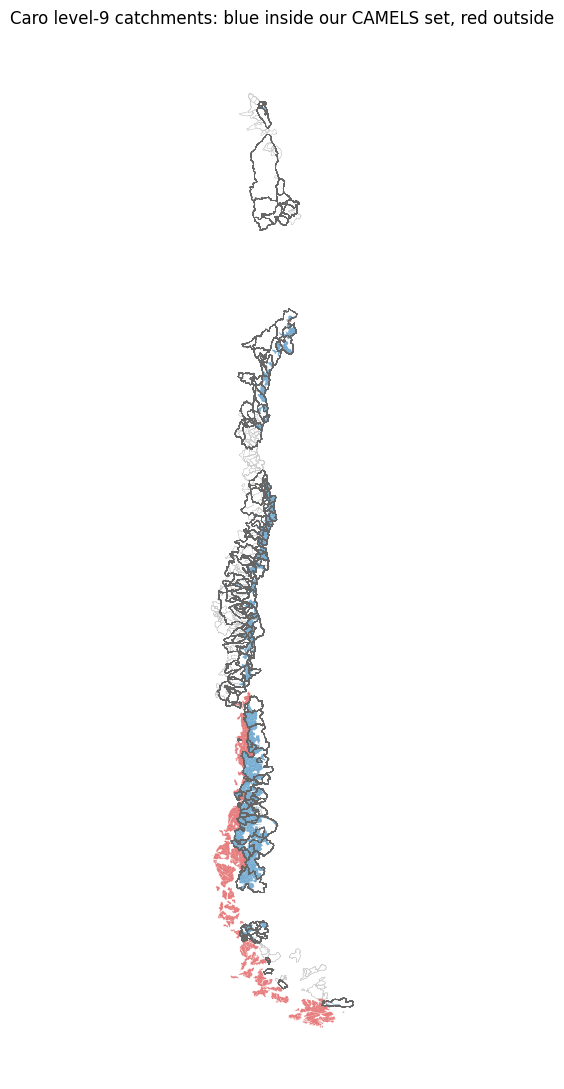

In [10]:
cg['in_camels'] = cg['id_basin'].isin(inside['id_basin'])

fig, ax = plt.subplots(figsize=(5, 11))
bounds_all.to_crs(AREA_CRS).boundary.plot(ax=ax, color='0.8', lw=0.3)
cm.boundary.plot(ax=ax, color='0.4', lw=0.5)
cg[~cg['in_camels']].plot(ax=ax, color='tab:red', alpha=0.6)
cg[cg['in_camels']].plot(ax=ax, color='tab:blue', alpha=0.6)
ax.set_axis_off()
ax.set_title('Caro level-9 catchments: blue inside our CAMELS set, red outside')
plt.tight_layout()
plt.show()

In [11]:
RGI_PATH = f'{BASE_PATH}/files_chile_OGGM_climate_comparison/RGI_BNA_Clusters.csv'
rgi = pd.read_csv(RGI_PATH)
g_rgi = gpd.GeoDataFrame(rgi, geometry=gpd.points_from_xy(rgi.CenLon, rgi.CenLat),
                         crs='EPSG:4326').to_crs(AREA_CRS)

# label each Caro catchment with the most common RGI cluster among glaciers inside it
pj = gpd.sjoin(g_rgi[['Cluster', 'geometry']], cg[['id_basin', 'geometry']],
               how='inner', predicate='within')
maj = pj.groupby('id_basin')['Cluster'].agg(lambda s: s.value_counts().idxmax())
cg['Cluster'] = cg['id_basin'].map(maj).fillna('none')

tab = (cg.groupby(['Cluster', 'in_camels'])['area_sim'].sum()
         .unstack(fill_value=0)
         .reindex(columns=[True, False], fill_value=0))
tab.columns = ['inside_our_basins_km2', 'outside_km2']
tab['total_km2'] = tab.sum(axis=1)
tab['pct_outside'] = 100 * tab['outside_km2'] / tab['total_km2']
print(tab.round(0))

         inside_our_basins_km2  outside_km2  total_km2  pct_outside
Cluster                                                            
DA1                      104.0          2.0      106.0          2.0
DA2                      209.0          0.0      209.0          0.0
DA3                      379.0          0.0      379.0          0.0
OT3                        6.0          0.0        6.0          0.0
WA1                      228.0          0.0      228.0          0.0
WA2                      806.0        744.0     1550.0         48.0
WA3                      114.0        250.0      364.0         69.0
WA4                     2294.0       1386.0     3680.0         38.0
WA5                        0.0        365.0      365.0        100.0
WA6                       61.0       1302.0     1363.0         96.0


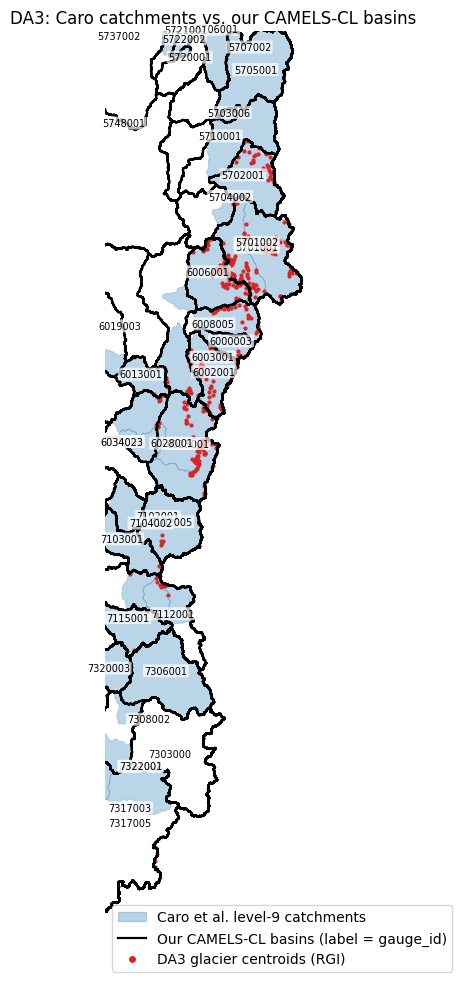

gauge_id  n_caro  caro_glacier_area_km2  our_glacier_area_km2  area_ratio_caro_to_ours
 5701001       2              41.556098                78.897                 0.526713
 5701002       3              72.913613                79.276                 0.919744
 5702001       1              72.699000                73.239                 0.992627
 5704002       5             182.617365               196.873                 0.927590
 5705001       1              56.712881                74.581                 0.760420
 5706001       1              76.336804                79.201                 0.963836
 5707002       2             133.049685               153.782                 0.865184
 5710001       7             315.667049               350.655                 0.900221
 5722002       2               1.748000                 4.450                 0.392809
 5737002       2               1.748000                 4.450                 0.392809
 5748001       9             317.415049    

In [12]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from shapely.geometry import box as sbox

CLUSTER = 'DA3'
PAD     = 0.15    # padding around the cluster's glaciers, as a fraction of its extent
RGI_PATH = f'{BASE_PATH}/files_chile_OGGM_climate_comparison/RGI_BNA_Clusters.csv'

rgi = pd.read_csv(RGI_PATH)
g_rgi = gpd.GeoDataFrame(rgi, geometry=gpd.points_from_xy(rgi.CenLon, rgi.CenLat),
                         crs='EPSG:4326').to_crs(AREA_CRS)
gl = g_rgi[g_rgi['Cluster'] == CLUSTER]

minx, miny, maxx, maxy = gl.total_bounds
px, py = (maxx - minx) * PAD, (maxy - miny) * PAD
bx = (minx - px, miny - py, maxx + px, maxy + py)
bb = sbox(*bx)

mine = cm[cm.intersects(bb)]          # your CAMELS polygons (glacierized set) in view
his  = cg[cg.intersects(bb)]          # Caro level-9 catchments in view

fig, ax = plt.subplots(figsize=(8, 10))
his.plot(ax=ax, facecolor='tab:blue', edgecolor='tab:blue', alpha=0.3, lw=0.6)
mine.boundary.plot(ax=ax, color='k', lw=1.6)
gl.plot(ax=ax, color='tab:red', markersize=4)
for _, r in mine.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r['gauge_id'], (p.x, p.y), fontsize=7, ha='center',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.7))
ax.set_xlim(bx[0], bx[2]); ax.set_ylim(bx[1], bx[3])
ax.set_axis_off()
ax.legend(handles=[
    Patch(facecolor='tab:blue', edgecolor='tab:blue', alpha=0.3, label='Caro et al. level-9 catchments'),
    Line2D([0], [0], color='k', lw=1.6, label='Our CAMELS-CL basins (label = gauge_id)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='tab:red', markersize=6,
           label=f'{CLUSTER} glacier centroids (RGI)')],
    loc='lower left')
ax.set_title(f'{CLUSTER}: Caro catchments vs. our CAMELS-CL basins')
plt.tight_layout()
plt.show()

# per-basin numbers for what is in view
print(summ[summ['gauge_id'].isin(mine['gauge_id'])]
      [['gauge_id', 'n_caro', 'caro_glacier_area_km2', 'our_glacier_area_km2', 'area_ratio_caro_to_ours']]
      .to_string(index=False))

In [13]:
chk = ov[ov['gauge_id'].isin(['7317003', '7317005']) & (ov['frac_in'] > 0.01)]
chk = chk.merge(caro[['id_basin', 'area_sim']], on='id_basin')
print(chk[['gauge_id', 'id_basin', 'frac_in', 'area_sim']].sort_values(['gauge_id', 'frac_in']).to_string(index=False))

gauge_id   id_basin  frac_in  area_sim
 7317003 6090908520 0.951761  4.495106
 7317003 6090912070 0.983717 10.696000
 7317005 6090908520 0.658578  4.495106
 7317005 6090912070 0.983717 10.696000


In [14]:
RGI_PATH = f'{BASE_PATH}/files_chile_OGGM_climate_comparison/RGI_BNA_Clusters.csv'
rgi = pd.read_csv(RGI_PATH)
assert 'Area' in rgi.columns, f'No Area column in RGI file. Columns: {list(rgi.columns)}'
g_rgi = gpd.GeoDataFrame(rgi, geometry=gpd.points_from_xy(rgi.CenLon, rgi.CenLat),
                         crs='EPSG:4326').to_crs(AREA_CRS)

# method 2: area-weighted (a catchment counts in proportion to how much of it is inside the basin)
w = ov[ov['id_basin'].isin(set(cg['id_basin'])) & (ov['frac_in'] > 0.01)] \
      .merge(caro[['id_basin', 'area_sim']], on='id_basin')
m2 = (w['area_sim'] * w['frac_in']).groupby(w['gauge_id']).sum()

# method 3: by glacier location (a catchment counts in proportion to its RGI ice that sits inside the basin)
p1 = gpd.sjoin(g_rgi[['Area', 'geometry']], cg[['id_basin', 'geometry']],
               how='inner', predicate='within').drop(columns='index_right')
tot = p1.groupby('id_basin')['Area'].sum()
p2 = gpd.sjoin(p1, cm[['gauge_id', 'geometry']], how='inner', predicate='within')
inn = p2.groupby(['id_basin', 'gauge_id'])['Area'].sum().reset_index()
inn['frac_gl'] = inn['Area'] / inn['id_basin'].map(tot)
inn = inn.merge(caro[['id_basin', 'area_sim']], on='id_basin')
m3 = (inn['area_sim'] * inn['frac_gl']).groupby(inn['gauge_id']).sum()

cmp = pd.DataFrame({'gauge_id': cm['gauge_id'].values})
cmp['our_glacier_area_km2'] = cmp['gauge_id'].map(glacier_area_by_gauge)
cmp['caro_90rule']          = cmp['gauge_id'].map(summ.set_index('gauge_id')['caro_glacier_area_km2'])
cmp['caro_area_weighted']   = cmp['gauge_id'].map(m2)
cmp['caro_glacier_loc']     = cmp['gauge_id'].map(m3)
cmp = cmp.fillna(0)
cmp = cmp[cmp['our_glacier_area_km2'] > 0]
for c in ['caro_90rule', 'caro_area_weighted', 'caro_glacier_loc']:
    cmp['ratio_' + c.replace('caro_', '')] = cmp[c] / cmp['our_glacier_area_km2']

r = cmp[[c for c in cmp.columns if c.startswith('ratio_')]]
print(r.describe().round(2))
print('\nShare of basins within 10% of ours:')
print((r.sub(1).abs() <= 0.1).mean().round(2))
print('\nThe two basins from before:')
print(cmp[cmp['gauge_id'].isin(['7317003', '7317005'])].round(2).to_string(index=False))

       ratio_90rule  ratio_area_weighted  ratio_glacier_loc
count        266.00               266.00             266.00
mean           0.55                 1.03               0.68
std            0.42                 4.11               0.35
min            0.00                 0.00               0.00
25%            0.00                 0.47               0.53
50%            0.66                 0.74               0.79
75%            0.88                 0.90               0.97
max            2.54                63.94               1.16

Share of basins within 10% of ours:
ratio_90rule           0.21
ratio_area_weighted    0.22
ratio_glacier_loc      0.35
dtype: float64

The two basins from before:
gauge_id  our_glacier_area_km2  caro_90rule  caro_area_weighted  caro_glacier_loc  ratio_90rule  ratio_area_weighted  ratio_glacier_loc
 7317003                 21.37        15.19               14.80             14.64          0.71                 0.69               0.69
 7317005               

In [15]:
import networkx as nx
from functools import lru_cache
from scipy.stats import ks_2samp

LEVEL1_IDS = None    # optional: paste your 70 Level 1 gauge_ids as strings

# ---------- nesting height among your glacierized basins ----------
cmv = cm.copy()
cmv['geometry'] = cmv.buffer(0)
area = cmv.set_index('gauge_id')['area_km2_poly']
pairs = gpd.overlay(cmv[['gauge_id', 'geometry']].rename(columns={'gauge_id': 'a'}),
                    cmv[['gauge_id', 'geometry']].rename(columns={'gauge_id': 'b'}),
                    how='intersection')
pairs = pairs[pairs['a'] != pairs['b']]
pairs['frac_a_in_b'] = (pairs.geometry.area / 1e6) / pairs['a'].map(area)
pairs = pairs[(pairs['frac_a_in_b'] >= CONTAIN_MIN) & (pairs['a'].map(area) < pairs['b'].map(area))]

G = nx.DiGraph()
G.add_nodes_from(cm['gauge_id'])
G.add_edges_from(zip(pairs['a'], pairs['b']))        # a -> b means a is inside b

@lru_cache(None)
def height(n):
    kids = list(G.predecessors(n))
    return 0 if not kids else 1 + max(height(k) for k in kids)

cm['height'] = cm['gauge_id'].map(height)
cm['terminal'] = cm['gauge_id'].map(lambda n: G.out_degree(n) == 0)
print('Nesting heights:', cm['height'].value_counts().sort_index().to_dict(), '| terminal:', int(cm['terminal'].sum()))

sets = {
    'height 0 (finest)':   cm['height'] == 0,
    'height 1':            cm['height'] == 1,
    'height 2+':           cm['height'] >= 2,
    'terminal (coarsest)': cm['terminal'],
    'all glacierized':     cm['height'] >= 0,
}
if LEVEL1_IDS is not None:
    sets['your Level 1 units'] = cm['gauge_id'].isin([str(x) for x in LEVEL1_IDS])

# ---------- Caro reference (Chilean catchments, RGI glacier area) ----------
cg['glac_frac_pct'] = 100 * cg['area_RGI'] / cg['area_km2_poly']
p1c = gpd.sjoin(g_rgi[['Cluster', 'geometry']], cg[['id_basin', 'geometry']],
                how='inner', predicate='within')
cg['Cluster'] = cg['id_basin'].map(p1c.groupby('id_basin')['Cluster'].agg(lambda s: s.value_counts().idxmax())).fillna('none')
caro_share = cg.groupby('Cluster')['area_RGI'].sum()
caro_share = caro_share / caro_share.sum()

cm['glac_frac_pct'] = 100 * cm['gauge_id'].map(glacier_area_by_gauge) / cm['area_km2_poly']
g_rgi['Cluster'] = g_rgi['Cluster'].astype(str)

rows = []
for name, mask in sets.items():
    sub = cm[mask]
    union = sub.geometry.buffer(0).unary_union
    cov = (cg.geometry.intersection(union).area / cg.geometry.area)
    coverage = 100 * (cov * cg['area_RGI']).sum() / cg['area_RGI'].sum()
    ours = g_rgi[g_rgi.geometry.within(union)].groupby('Cluster')['Area'].sum()
    ours = ours / ours.sum()
    idx = caro_share.index.union(ours.index)
    tvd = 0.5 * (caro_share.reindex(idx, fill_value=0) - ours.reindex(idx, fill_value=0)).abs().sum()
    rows.append(dict(
        basin_set=name, n_basins=len(sub),
        median_area_km2=sub['area_km2_poly'].median(),
        median_glac_pct=sub['glac_frac_pct'].median(),
        KS_basin_area=ks_2samp(np.log10(sub['area_km2_poly']), np.log10(cg['area_km2_poly'])).statistic,
        KS_glac_pct=ks_2samp(sub['glac_frac_pct'].dropna(), cg['glac_frac_pct'].dropna()).statistic,
        coverage_of_Caro_ice_pct=coverage,
        regional_mix_diff=tvd))

print(f'\nCaro reference: n={len(cg)}, median area {cg["area_km2_poly"].median():.0f} km2, '
      f'median glaciated {cg["glac_frac_pct"].median():.1f}%')
print(pd.DataFrame(rows).round(2).to_string(index=False))

Nesting heights: {0: 103, 1: 50, 2: 34, 3: 24, 4: 17, 5: 12, 6: 7, 7: 7, 8: 5, 9: 3, 10: 2, 11: 1, 12: 1} | terminal: 41

Caro reference: n=497, median area 270 km2, median glaciated 2.7%
          basin_set  n_basins  median_area_km2  median_glac_pct  KS_basin_area  KS_glac_pct  coverage_of_Caro_ice_pct  regional_mix_diff
  height 0 (finest)       103           520.17             0.89           0.33         0.26                     14.96               0.30
           height 1        50          1480.74             0.75           0.77         0.36                     22.49               0.35
          height 2+       113          5507.22             0.46           0.94         0.47                     37.25               0.24
terminal (coarsest)        41          5685.67             0.43           0.76         0.37                     41.08               0.19
    all glacierized       266          1981.01             0.56           0.67         0.35                     41.08          

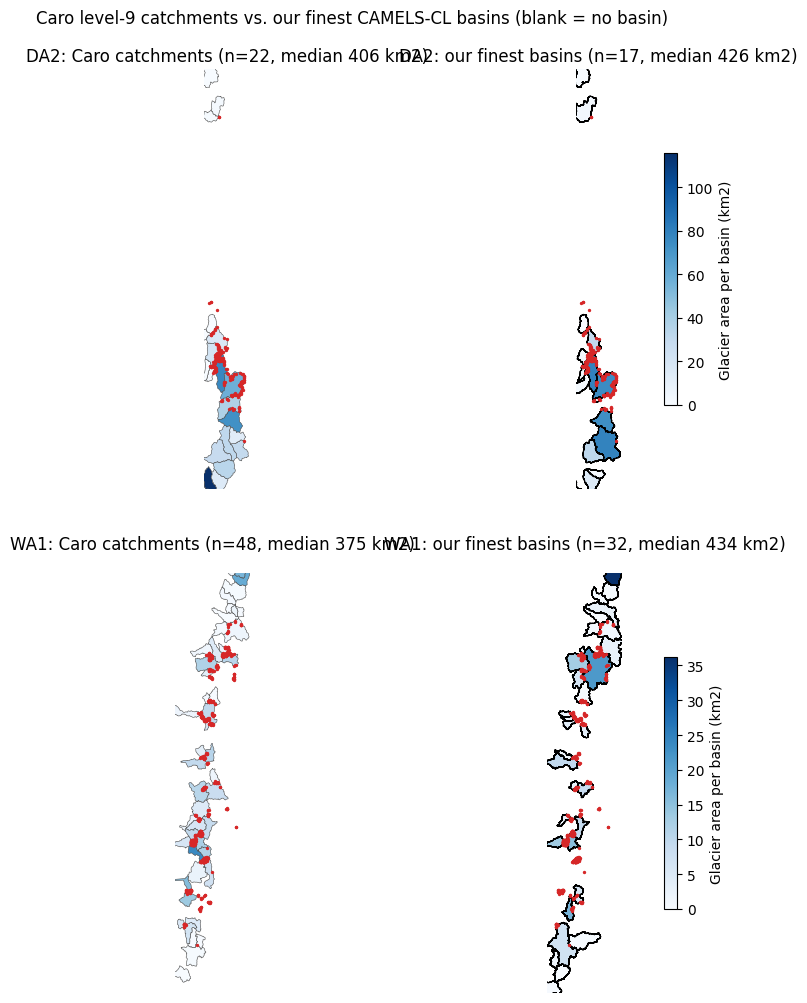

In [16]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

CLUSTERS = ['DA2', 'WA1']
PAD = 0.15

finest = cm[cm['height'] == 0].copy()
finest['glac_km2'] = finest['gauge_id'].map(glacier_area_by_gauge)

fig, axes = plt.subplots(len(CLUSTERS), 2, figsize=(11, 6 * len(CLUSTERS)))
for i, cl in enumerate(CLUSTERS):
    gl = g_rgi[g_rgi['Cluster'].astype(str) == cl]
    minx, miny, maxx, maxy = gl.total_bounds
    px, py = (maxx - minx) * PAD, (maxy - miny) * PAD
    bx = (minx - px, miny - py, maxx + px, maxy + py)
    bb = sbox(*bx)

    his  = cg[cg.intersects(bb)]
    mine = finest[finest.intersects(bb)]
    vmax = max(his['area_RGI'].max(), mine['glac_km2'].max())

    his.plot(ax=axes[i, 0], column='area_RGI', cmap='Blues', vmin=0, vmax=vmax,
             edgecolor='0.3', lw=0.4)
    mine.plot(ax=axes[i, 1], column='glac_km2', cmap='Blues', vmin=0, vmax=vmax,
              edgecolor='k', lw=0.8)

    for j, ax in enumerate(axes[i]):
        gl.plot(ax=ax, color='tab:red', markersize=2)
        ax.set_xlim(bx[0], bx[2]); ax.set_ylim(bx[1], bx[3])
        ax.set_axis_off()
    axes[i, 0].set_title(f'{cl}: Caro catchments (n={len(his)}, median {his["area_km2_poly"].median():.0f} km2)')
    axes[i, 1].set_title(f'{cl}: our finest basins (n={len(mine)}, median {mine["area_km2_poly"].median():.0f} km2)')

    sm = ScalarMappable(norm=Normalize(0, vmax), cmap='Blues')
    fig.colorbar(sm, ax=axes[i, :].tolist(), shrink=0.6, label='Glacier area per basin (km2)')

fig.suptitle('Caro level-9 catchments vs. our finest CAMELS-CL basins (blank = no basin)', y=0.93)
plt.show()

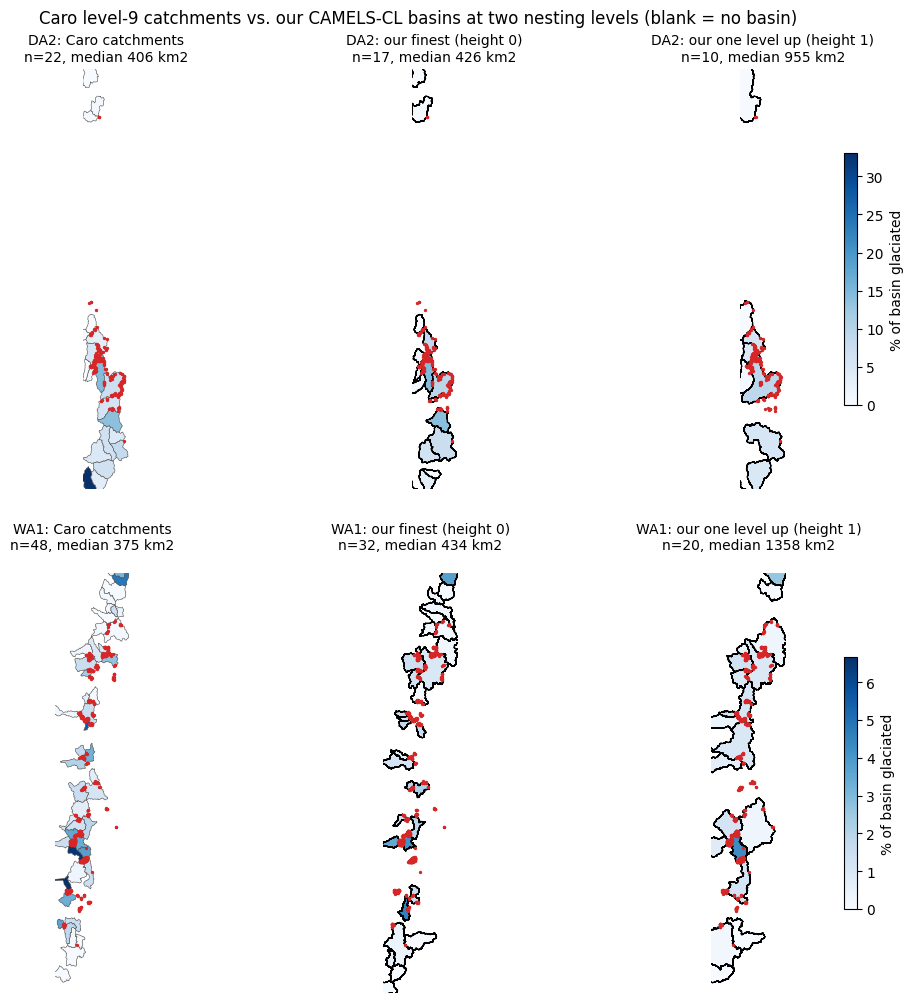

In [17]:
CLUSTERS = ['DA2', 'WA1']
PAD = 0.15

finest = cm[cm['height'] == 0]
level1 = cm[cm['height'] == 1]
# cg['glac_frac_pct'] and cm['glac_frac_pct'] come from cell B (% of basin that is glacier, RGI area)

fig, axes = plt.subplots(len(CLUSTERS), 3, figsize=(15, 6 * len(CLUSTERS)))
for i, cl in enumerate(CLUSTERS):
    gl = g_rgi[g_rgi['Cluster'].astype(str) == cl]
    minx, miny, maxx, maxy = gl.total_bounds
    px, py = (maxx - minx) * PAD, (maxy - miny) * PAD
    bx = (minx - px, miny - py, maxx + px, maxy + py)
    bb = sbox(*bx)

    panels = [('Caro catchments', cg[cg.intersects(bb)], '0.3', 0.4),
              ('our finest (height 0)', finest[finest.intersects(bb)], 'k', 0.8),
              ('our one level up (height 1)', level1[level1.intersects(bb)], 'k', 0.8)]
    vmax = max(p[1]['glac_frac_pct'].max() for p in panels)

    for j, (label, df, ec, lw) in enumerate(panels):
        ax = axes[i, j]
        df.plot(ax=ax, column='glac_frac_pct', cmap='Blues', vmin=0, vmax=vmax,
                edgecolor=ec, lw=lw)
        gl.plot(ax=ax, color='tab:red', markersize=2)
        ax.set_xlim(bx[0], bx[2]); ax.set_ylim(bx[1], bx[3])
        ax.set_axis_off()
        ax.set_title(f'{cl}: {label}\nn={len(df)}, median {df["area_km2_poly"].median():.0f} km2', fontsize=10)

    sm = ScalarMappable(norm=Normalize(0, vmax), cmap='Blues')
    fig.colorbar(sm, ax=axes[i, :].tolist(), shrink=0.6, label='% of basin glaciated')

fig.suptitle('Caro level-9 catchments vs. our CAMELS-CL basins at two nesting levels (blank = no basin)', y=0.93)
plt.show()

In [18]:
fin = cm[cm['height'] == 0][['gauge_id', 'area_km2_poly', 'geometry']].copy()
fin['geometry'] = fin.buffer(0)

# 1) polygon overlap between finest basins
o = gpd.overlay(fin.rename(columns={'gauge_id': 'a', 'area_km2_poly': 'area_a'}),
                fin.rename(columns={'gauge_id': 'b', 'area_km2_poly': 'area_b'}),
                how='intersection')
o = o[o['a'] < o['b']]                                   # each pair once
o['overlap_km2'] = o.geometry.area / 1e6
o['frac_of_smaller'] = o['overlap_km2'] / np.minimum(o['area_a'], o['area_b'])
o = o[o['frac_of_smaller'] > 0.001].sort_values('frac_of_smaller', ascending=False)

print(f'Finest basins: {len(fin)}')
print(f'Pairs that overlap (> 0.1% of the smaller basin): {len(o)}')
print(f'  nearly the same basin (> 50% of the smaller):   {(o["frac_of_smaller"] > 0.5).sum()}')
print(f'  partial overlap (5% to 50%):                    {((o["frac_of_smaller"] > 0.05) & (o["frac_of_smaller"] <= 0.5)).sum()}')
print(f'  slivers (< 5%):                                 {(o["frac_of_smaller"] <= 0.05).sum()}')
print(o[['a', 'b', 'area_a', 'area_b', 'overlap_km2', 'frac_of_smaller']].head(15).round(2).to_string(index=False))

# 2) what it means for the ice: glaciers that sit inside more than one finest basin
pj = gpd.sjoin(g_rgi[['Area', 'geometry']], fin[['gauge_id', 'geometry']],
               how='inner', predicate='within')
n_in = pj.groupby(pj.index).size()
ice  = pj['Area'].groupby(pj.index).first()
print(f'\nGlaciers inside a finest basin: {len(n_in)} | inside more than one: {(n_in > 1).sum()}')
print(f'Ice counted more than once: {(ice * (n_in - 1)).sum():.1f} km2 of {ice.sum():.1f} km2 total')

Finest basins: 103
Pairs that overlap (> 0.1% of the smaller basin): 2
  nearly the same basin (> 50% of the smaller):   0
  partial overlap (5% to 50%):                    0
  slivers (< 5%):                                 2
       a        b  area_a  area_b  overlap_km2  frac_of_smaller
10304001 10306001 1724.31  308.38         1.73             0.01
11335002 11500002 1768.64  551.28         1.21             0.00

Glaciers inside a finest basin: 3332 | inside more than one: 0
Ice counted more than once: 0.0 km2 of 2606.4 km2 total


In [20]:
SOUTH = ['WA3', 'WA4', 'WA5', 'WA6']

g = g_rgi.copy()
g['Cluster'] = g['Cluster'].astype(str)
g = g[~g['Cluster'].isin(SOUTH)].copy()

g['in_finest'] = g.geometry.within(union_fin)
g['in_any']    = g.geometry.within(union_all)
g['where'] = np.where(g['in_finest'], '1 inside a finest basin',
              np.where(g['in_any'], '2 only inside a larger nested gauge', '3 in no gauged basin'))

tot = g['Area'].sum()
t = g.groupby('where')['Area'].agg(n_glaciers='count', ice_km2='sum')
t['pct_of_ice'] = 100 * t['ice_km2'] / tot
print(f'Excluding {SOUTH}: {len(g)} glaciers | {tot:.0f} km2')
print(t.round(1))

gauged = t.loc[t.index.str.startswith(('1', '2')), 'ice_km2'].sum()
print(f'\nFinest basins hold {100 * t.loc["1 inside a finest basin", "ice_km2"] / gauged:.0f}% of the gauged ice')

by_cl = g.pivot_table(index='Cluster', columns='where', values='Area', aggfunc='sum', fill_value=0)
print('\n% of each region\'s ice:')
print((100 * by_cl.div(by_cl.sum(axis=1), axis=0)).round(0))

Excluding ['WA3', 'WA4', 'WA5', 'WA6']: 4668 glaciers | 2852 km2
                                     n_glaciers  ice_km2  pct_of_ice
where                                                               
1 inside a finest basin                    2085   1198.6        42.0
2 only inside a larger nested gauge        1551    853.8        29.9
3 in no gauged basin                       1032    799.4        28.0

Finest basins hold 58% of the gauged ice

% of each region's ice:
where    1 inside a finest basin  2 only inside a larger nested gauge  \
Cluster                                                                 
DA1                         66.0                                 28.0   
DA2                         76.0                                 24.0   
DA3                         62.0                                 38.0   
OT3                         64.0                                 31.0   
WA1                         47.0                                 53.0   
WA2         

In [21]:
union_all = cm.geometry.buffer(0).unary_union

g = g_rgi.copy()
g['Cluster'] = g['Cluster'].astype(str)
g['gauged'] = g.geometry.within(union_all)

t = g.groupby('Cluster')['gauged'].agg(total_glaciers='size', in_gauged_basin='sum')
t.loc['ALL'] = t.sum()
t['pct_in_gauged_basin'] = (100 * t['in_gauged_basin'] / t['total_glaciers']).round(0)
print(t)

         total_glaciers  in_gauged_basin  pct_in_gauged_basin
Cluster                                                      
DA1                 422              400                 95.0
DA2                 200              196                 98.0
DA3                 410              408                100.0
OT3                  34               32                 94.0
WA1                 678              669                 99.0
WA2                2924             1931                 66.0
WA3                 447              107                 24.0
WA4                4749             3087                 65.0
WA5                 711                0                  0.0
WA6                2671               53                  2.0
ALL               13246             6883                 52.0


In [22]:
print(rgi.shape)
print(list(rgi.columns))

id_col = next((c for c in rgi.columns if c.lower() in ('rgiid', 'rgi_id')), None)
if id_col:
    print('\nID prefixes (RGI60-16 / RGI60-17 etc.):')
    print(rgi[id_col].str[:9].value_counts())
    print('duplicate IDs:', rgi[id_col].duplicated().sum())
print('\nlat range:', rgi['CenLat'].min(), rgi['CenLat'].max(),
      '| lon range:', rgi['CenLon'].min(), rgi['CenLon'].max())
for c in ['TermType', 'O1Region', 'O2Region', 'Status']:
    if c in rgi.columns:
        print(f'\n{c}:'); print(rgi[c].value_counts(dropna=False).head())

# glaciers outside Chile's border (5 km tolerance for the coast); chile_geom is from cell 2
inside = g_rgi.geometry.within(chile_geom.buffer(5000))
print(f'\nInside Chile: {inside.sum()} | outside (likely Argentina): {(~inside).sum()}')
print(g_rgi.loc[~inside, 'Cluster'].astype(str).value_counts())

(13246, 27)
['FID', 'RGIId', 'GLIMSId', 'BgnDate', 'EndDate', 'CenLon', 'CenLat', 'O1Region', 'O2Region', 'Area', 'Zmin', 'Zmax', 'Zmed', 'Slope', 'Aspect', 'Lmax', 'Status', 'Connect', 'Form', 'TermType', 'Surging', 'Linkages', 'Name', 'Cluster', 'COD_CUEN', 'NOM_CUEN', 'Area_km2']

ID prefixes (RGI60-16 / RGI60-17 etc.):
RGIId
RGI60-17.    13201
RGI60-16.       45
Name: count, dtype: int64
duplicate IDs: 0

lat range: -55.466 -18.0375 | lon range: -74.8233 -67.6441

TermType:
TermType
0    13043
2      118
1       85
Name: count, dtype: int64

O1Region:
O1Region
17    13201
16       45
Name: count, dtype: int64

O2Region:
O2Region
1    8823
2    4423
Name: count, dtype: int64

Status:
Status
0    13246
Name: count, dtype: int64

Inside Chile: 12291 | outside (likely Argentina): 955
Cluster
WA4    495
WA2    314
DA1     90
WA3     35
WA6     21
Name: count, dtype: int64


In [23]:
g = g_rgi.copy()
g['Cluster'] = g['Cluster'].astype(str)
g['gauged'] = g.geometry.within(cm.geometry.buffer(0).unary_union)
g['n_gauged'] = g['gauged'].astype(int)
g['area_gauged'] = g['Area'].where(g['gauged'], 0)

tab = g.groupby('Cluster').agg(glaciers=('Area', 'size'),
                               area_km2=('Area', 'sum'),
                               glaciers_gauged=('n_gauged', 'sum'),
                               area_gauged_km2=('area_gauged', 'sum'))
tab.loc['All'] = tab.sum()
tab['pct_glaciers_gauged'] = 100 * tab['glaciers_gauged'] / tab['glaciers']
tab['pct_area_gauged'] = 100 * tab['area_gauged_km2'] / tab['area_km2']
order = ['OT3', 'DA1', 'DA2', 'DA3', 'WA1', 'WA2', 'WA3', 'WA4', 'WA5', 'WA6', 'All']
print(tab.reindex(order).round(0).to_string())

         glaciers  area_km2  glaciers_gauged  area_gauged_km2  pct_glaciers_gauged  pct_area_gauged
Cluster                                                                                            
OT3          34.0      13.0             32.0             13.0                 94.0             95.0
DA1         422.0     148.0            400.0            140.0                 95.0             94.0
DA2         200.0     254.0            196.0            253.0                 98.0            100.0
DA3         410.0     391.0            408.0            390.0                100.0            100.0
WA1         678.0     308.0            669.0            307.0                 99.0            100.0
WA2        2924.0    1738.0           1931.0            949.0                 66.0             55.0
WA3         447.0   10947.0            107.0           1470.0                 24.0             13.0
WA4        4749.0    6474.0           3087.0           3278.0                 65.0             51.0


In [24]:
  print(rgi[rgi['TermType'].isin([1, 2])].groupby('Cluster').size())

Cluster
WA2     4
WA3    47
WA4    70
WA5    18
WA6    64
dtype: int64


In [25]:
import networkx as nx

# Gauges that pass your data screen. None = every glacierized CAMELS basin (geometry only, no data screen yet).
VALID_IDS = None
valid = set(cm['gauge_id']) if VALID_IDS is None else {str(v) for v in VALID_IDS} & set(cm['gauge_id'])

# glacier -> every CAMELS polygon it sits in
gl = g_rgi[['Area', 'Cluster', 'geometry']].copy()
gl['Cluster'] = gl['Cluster'].astype(str)
pj = gpd.sjoin(gl, cm[['gauge_id', 'area_km2_poly', 'geometry']], how='inner', predicate='within')
pj['gid'] = pj.index
pj = pj.reset_index(drop=True)
members = pj.groupby('gauge_id')['gid'].apply(list).to_dict()

# G (from the nesting cell): a -> b means basin a is inside basin b. H keeps only direct containment.
H = nx.transitive_reduction(G)

def pick(n):                       # coarsest valid basin on each chain, falling back to sub-basins
    if n in valid:
        return [n]
    return [u for k in H.predecessors(n) for u in pick(k)]

finest   = set(cm.loc[cm['height'] == 0, 'gauge_id'])
terminal = {n for n in G.nodes if G.out_degree(n) == 0}
tops     = list(terminal)

units_A = sorted(valid & finest)
units_B = sorted(valid & terminal)
units_C = sorted({u for t in tops for u in pick(t)})

# D: each glacier goes to the smallest valid gauge that contains it
pv  = pj[pj['gauge_id'].isin(valid)]
asg = pv.loc[pv.groupby('gid')['area_km2_poly'].idxmin(), ['gid', 'gauge_id']]
members_D = asg.groupby('gauge_id')['gid'].apply(list).to_dict()
units_D = sorted(members_D)

rows, per_cl = [], {}
def add(name, units, mem):
    all_ids = [g for u in units for g in mem.get(u, [])]
    ids = set(all_ids)
    sub = gl.loc[list(ids)]
    rows.append(dict(strategy=name, basins_used=len(units),
                     glaciers=len(ids), pct_glaciers=100 * len(ids) / len(gl),
                     area_km2=sub['Area'].sum(), pct_area=100 * sub['Area'].sum() / gl['Area'].sum(),
                     double_counted=len(all_ids) - len(ids)))
    per_cl[name] = sub['Cluster'].value_counts()

add('A finest only',                   units_A, members)
add('B coarsest (terminal) only',      units_B, members)
add('C coarsest valid, else sub-basins', units_C, members)
add('D innermost valid gauge',         units_D, members_D)

print(f'Valid gauges: {len(valid)} | glaciers: {len(gl)} | area: {gl["Area"].sum():.0f} km2')
print(pd.DataFrame(rows).round(1).to_string(index=False))
print(f'\nStrategy D units: {len(units_D)} total, {len(set(units_D) & finest)} finest basins, '
      f'{len(set(units_D) - finest)} in-between units that need flow differencing')

order = ['OT3', 'DA1', 'DA2', 'DA3', 'WA1', 'WA2', 'WA3', 'WA4', 'WA5', 'WA6']
tab = pd.DataFrame(per_cl).fillna(0).astype(int).reindex(order, fill_value=0)
tab.insert(0, 'all glaciers', gl['Cluster'].value_counts().reindex(order, fill_value=0))
print('\nGlaciers covered, by region:')
print(tab)

Valid gauges: 266 | glaciers: 13246 | area: 27499 km2
                         strategy  basins_used  glaciers  pct_glaciers  area_km2  pct_area  double_counted
                    A finest only          103      3332          25.2    2606.4       9.5               0
       B coarsest (terminal) only           41      6882          52.0    7338.6      26.7               0
C coarsest valid, else sub-basins           41      6882          52.0    7338.6      26.7               0
          D innermost valid gauge          157      6883          52.0    7338.7      26.7               0

Strategy D units: 157 total, 103 finest basins, 54 in-between units that need flow differencing

Glaciers covered, by region:
         all glaciers  A finest only  B coarsest (terminal) only  \
Cluster                                                            
OT3                34             19                          32   
DA1               422            263                         399   
DA2         

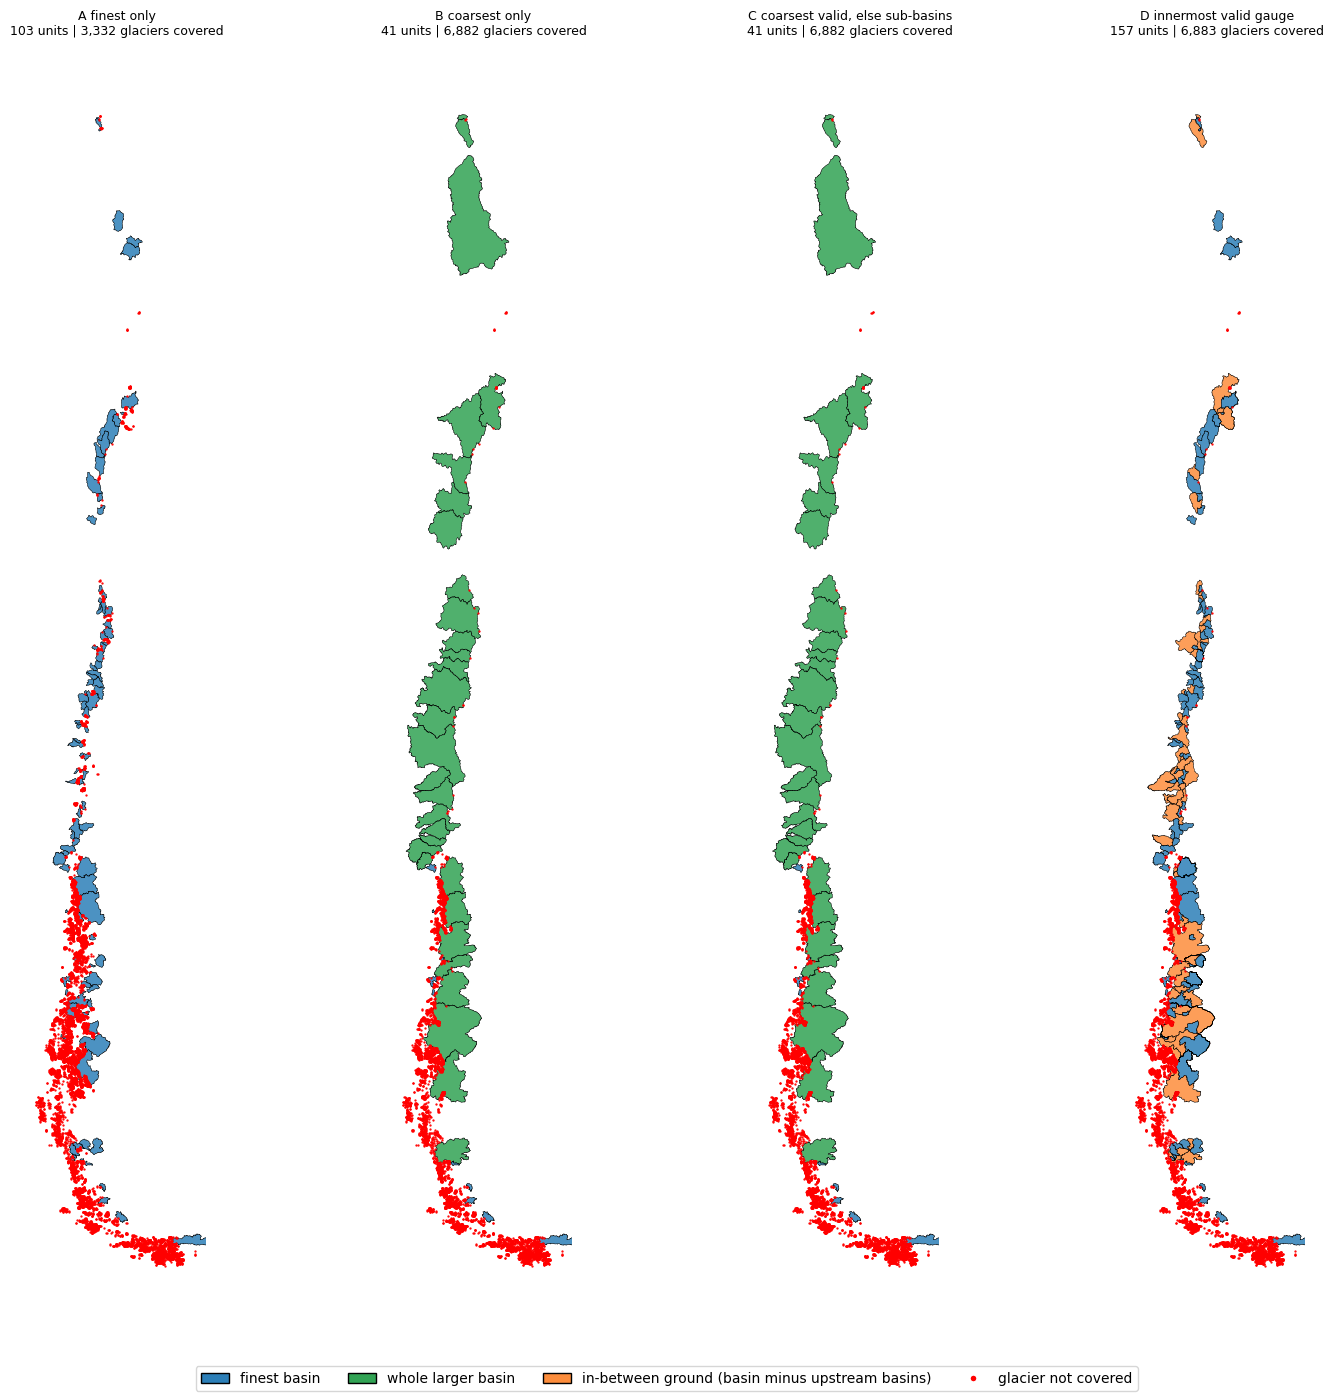

In [26]:
from shapely.ops import unary_union
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

CLUSTERS = None    # None = all of Chile; or e.g. ['DA2', 'WA1'] to zoom into regions
COL = {'finest': '#2c7fb8', 'whole': '#31a354', 'between': '#fd8d3c'}

geom = cm.set_index('gauge_id').geometry.buffer(0)
height0 = set(cm.loc[cm['height'] == 0, 'gauge_id'])

def layer_whole(units):                      # strategies A, B, C: whole basins
    return gpd.GeoDataFrame(
        {'gauge_id': units, 'kind': ['finest' if u in height0 else 'whole' for u in units]},
        geometry=[geom[u] for u in units], crs=AREA_CRS)

def layer_D(units):                          # strategy D: basin minus the D units nested inside it
    Dset, gs, kinds = set(units), [], []
    for u in units:
        inner = [geom[d] for d in G.predecessors(u) if d in Dset]
        gs.append(geom[u].difference(unary_union(inner)) if inner else geom[u])
        kinds.append('finest' if u in height0 else ('between' if inner else 'whole'))
    return gpd.GeoDataFrame({'gauge_id': units, 'kind': kinds}, geometry=gs, crs=AREA_CRS)

def covered(units, mem):
    return {g for u in units for g in mem.get(u, [])}

strategies = {
    'A finest only':                      (layer_whole(units_A), covered(units_A, members), len(units_A)),
    'B coarsest only':                    (layer_whole(units_B), covered(units_B, members), len(units_B)),
    'C coarsest valid, else sub-basins':  (layer_whole(units_C), covered(units_C, members), len(units_C)),
    'D innermost valid gauge':            (layer_D(units_D),     covered(units_D, members_D), len(units_D)),
}

sel = gl[gl['Cluster'].isin(CLUSTERS)] if CLUSTERS else gl
minx, miny, maxx, maxy = sel.total_bounds
px, py = (maxx - minx) * 0.05, (maxy - miny) * 0.05

fig, axes = plt.subplots(1, 4, figsize=(16, 14))
for ax, (name, (layer, cov, n)) in zip(axes, strategies.items()):
    layer.plot(ax=ax, color=layer['kind'].map(COL), edgecolor='k', lw=0.3, alpha=0.85)
    unc = gl.loc[gl.index.difference(list(cov))]
    unc.plot(ax=ax, color='red', markersize=0.4)
    ax.set_xlim(minx - px, maxx + px); ax.set_ylim(miny - py, maxy + py)
    ax.set_axis_off()
    ax.set_title(f'{name}\n{n} units | {len(cov):,} glaciers covered', fontsize=9)

fig.legend(handles=[
    Patch(facecolor=COL['finest'], edgecolor='k', label='finest basin'),
    Patch(facecolor=COL['whole'], edgecolor='k', label='whole larger basin'),
    Patch(facecolor=COL['between'], edgecolor='k', label='in-between ground (basin minus upstream basins)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=5, label='glacier not covered')],
    loc='lower center', ncol=4)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [29]:
import networkx as nx

THRESHOLDS = [0.10, 0.30, 0.40, 0.50]

# how much of each basin lies inside each other basin (computed once)
cmv = cm.copy()
cmv['geometry'] = cmv.buffer(0)
area = cmv.set_index('gauge_id')['area_km2_poly']
pr = gpd.overlay(cmv[['gauge_id', 'geometry']].rename(columns={'gauge_id': 'a'}),
                 cmv[['gauge_id', 'geometry']].rename(columns={'gauge_id': 'b'}),
                 how='intersection')
pr = pr[pr['a'] != pr['b']]
pr['frac_a_in_b'] = (pr.geometry.area / 1e6) / pr['a'].map(area)
pr = pr[pr['a'].map(area) < pr['b'].map(area)]

# most glaciers any choice of valid basins could cover
ceiling = pj.loc[pj['gauge_id'].isin(valid), 'gid'].nunique()

def run_C(t):
    e = pr[pr['frac_a_in_b'] >= t]
    Gt = nx.DiGraph()
    Gt.add_nodes_from(cm['gauge_id'])
    Gt.add_edges_from(zip(e['a'], e['b']))              # a -> b: a counted as inside b
    Ht = nx.transitive_reduction(Gt)

    def pick(n):                                        # outermost valid basin, else go inside
        if n in valid:
            return [n]
        return [u for k in Ht.predecessors(n) for u in pick(k)]

    tops = [n for n in Gt.nodes if Gt.out_degree(n) == 0]
    units = sorted({u for tp in tops for u in pick(tp)})
    all_ids = [g for u in units for g in members.get(u, [])]
    return units, all_ids, len(tops)

base_units = set(run_C(0.90)[0])
rows = []
for t in THRESHOLDS:
    units, all_ids, n_out = run_C(t)
    ids = set(all_ids)
    rows.append(dict(cutoff=f'{t:.0%}',
                     outermost_basins=n_out,
                     basins_used=len(units),
                     glaciers=len(ids),
                     pct_of_all=round(100 * len(ids) / len(gl), 1),
                     missed_vs_ceiling=ceiling - len(ids),
                     area_km2=round(gl.loc[list(ids), 'Area'].sum()),
                     double_counted=len(all_ids) - len(ids),
                     units_differ_from_90=len(set(units) ^ base_units)))
print(f'Ceiling (glaciers in any valid basin): {ceiling}')
print(pd.DataFrame(rows).to_string(index=False))

Ceiling (glaciers in any valid basin): 6883
cutoff  outermost_basins  basins_used  glaciers  pct_of_all  missed_vs_ceiling  area_km2  double_counted  units_differ_from_90
   10%                41           41      6882        52.0                  1      7339               0                     0
   30%                41           41      6882        52.0                  1      7339               0                     0
   40%                41           41      6882        52.0                  1      7339               0                     0
   50%                41           41      6882        52.0                  1      7339               0                     0


In [30]:
import calendar

CAMELS_FULL = f'{BASE_PATH}/Full_CAMELS_all_basins/CAMELS_CL_v202201'
SUMMER_THRESHOLD, WINTER_THRESHOLD, LAT_BOUNDARY = 0.70, 0.50, -38.0

q_day = pd.read_csv(f'{CAMELS_FULL}/q_m3s_day.csv', parse_dates=['date'])
q_day = q_day[(q_day['year'] >= 1999) & (q_day['year'] <= 2019)]

gids = [g for g in cm['gauge_id'] if g in q_day.columns]
ok = q_day[gids].notna() & (q_day[gids] >= 0)
cnt = ok.groupby([q_day['year'], q_day['month']]).sum()
dim = pd.Series([calendar.monthrange(y, m)[1] for y, m in cnt.index], index=cnt.index)
frac = cnt.div(dim, axis=0)          # share of days with valid data, by (year, month) and gauge

def complete_years(g):
    f = frac[g]
    yrs = []
    for y in range(2000, 2020):
        summer = [f.get((y - 1, 12), 0)] + [f.get((y, m), 0) for m in (1, 2, 3, 4)]
        winter = [f.get((y, m), 0) for m in range(5, 12)]
        if all(s >= SUMMER_THRESHOLD for s in summer) and sum(w >= WINTER_THRESHOLD for w in winter) >= 4:
            yrs.append(y)
    return yrs

lat = bounds_all.set_index('gauge_id').geometry.centroid.y
passes = {}
for g in cm['gauge_id']:
    yrs = complete_years(g) if g in gids else []
    n_pre, n_post = sum(y <= 2009 for y in yrs), sum(y >= 2010 for y in yrs)
    passes[g] = (n_pre >= 5 and n_post >= 5) if lat[g] > LAT_BOUNDARY else len(yrs) >= 10

VALID_IDS = {g for g, v in passes.items() if v}

finest_ids   = set(cm.loc[cm['height'] == 0, 'gauge_id'])
terminal_ids = {n for n in G.nodes if G.out_degree(n) == 0}
print(f'Pass completeness: {len(VALID_IDS)} of {len(cm)} glacierized basins')
print(f'  finest basins that pass:   {len(VALID_IDS & finest_ids)} of {len(finest_ids)}')
print(f'  terminal basins that pass: {len(VALID_IDS & terminal_ids)} of {len(terminal_ids)}')
print('Terminal basins that fail:', sorted(terminal_ids - VALID_IDS))

Pass completeness: 143 of 266 glacierized basins
  finest basins that pass:   54 of 103
  terminal basins that pass: 27 of 41
Terminal basins that fail: ['10122001', '1021001', '10683002', '11130001', '11147001', '11151001', '11405001', '12825002', '2120001', '3453001', '3826001', '4335001', '5423005', '6019003']


In [31]:
import networkx as nx

# uses VALID_IDS from the completeness cell (gauges that pass the data screen)
valid = {str(v) for v in VALID_IDS} & set(cm['gauge_id'])

# glacier -> every CAMELS polygon it sits in
gl = g_rgi[['Area', 'Cluster', 'geometry']].copy()
gl['Cluster'] = gl['Cluster'].astype(str)
pj = gpd.sjoin(gl, cm[['gauge_id', 'area_km2_poly', 'geometry']], how='inner', predicate='within')
pj['gid'] = pj.index
pj = pj.reset_index(drop=True)
members = pj.groupby('gauge_id')['gid'].apply(list).to_dict()

# G (from the nesting cell): a -> b means basin a is inside basin b. H keeps only direct containment.
H = nx.transitive_reduction(G)

def pick(n):                       # coarsest valid basin on each chain, falling back to sub-basins
    if n in valid:
        return [n]
    return [u for k in H.predecessors(n) for u in pick(k)]

finest   = set(cm.loc[cm['height'] == 0, 'gauge_id'])
terminal = {n for n in G.nodes if G.out_degree(n) == 0}
tops     = list(terminal)

units_A = sorted(valid & finest)
units_B = sorted(valid & terminal)
units_C = sorted({u for t in tops for u in pick(t)})

# D: each glacier goes to the smallest valid gauge that contains it
pv  = pj[pj['gauge_id'].isin(valid)]
asg = pv.loc[pv.groupby('gid')['area_km2_poly'].idxmin(), ['gid', 'gauge_id']]
members_D = asg.groupby('gauge_id')['gid'].apply(list).to_dict()
units_D = sorted(members_D)

rows, per_cl = [], {}
def add(name, units, mem):
    all_ids = [g for u in units for g in mem.get(u, [])]
    ids = set(all_ids)
    sub = gl.loc[list(ids)]
    rows.append(dict(strategy=name, basins_used=len(units),
                     glaciers=len(ids), pct_glaciers=100 * len(ids) / len(gl),
                     area_km2=sub['Area'].sum(), pct_area=100 * sub['Area'].sum() / gl['Area'].sum(),
                     double_counted=len(all_ids) - len(ids)))
    per_cl[name] = sub['Cluster'].value_counts()

add('A finest only',                     units_A, members)
add('B coarsest (terminal) only',        units_B, members)
add('C coarsest valid, else sub-basins', units_C, members)
add('D innermost valid gauge',           units_D, members_D)

print(f'Valid gauges: {len(valid)} | glaciers: {len(gl)} | area: {gl["Area"].sum():.0f} km2')
print(pd.DataFrame(rows).round(1).to_string(index=False))
print(f'\nStrategy D units: {len(units_D)} total, {len(set(units_D) & finest)} finest basins, '
      f'{len(set(units_D) - finest)} in-between units that need flow differencing')

order = ['OT3', 'DA1', 'DA2', 'DA3', 'WA1', 'WA2', 'WA3', 'WA4', 'WA5', 'WA6']
tab = pd.DataFrame(per_cl).fillna(0).astype(int).reindex(order, fill_value=0)
tab.insert(0, 'all glaciers', gl['Cluster'].value_counts().reindex(order, fill_value=0))
print('\nGlaciers covered, by region:')
print(tab)

Valid gauges: 143 | glaciers: 13246 | area: 27499 km2
                         strategy  basins_used  glaciers  pct_glaciers  area_km2  pct_area  double_counted
                    A finest only           54      2087          15.8    1880.2       6.8               0
       B coarsest (terminal) only           27      6084          45.9    6764.1      24.6               0
C coarsest valid, else sub-basins           40      6577          49.7    7157.9      26.0               0
          D innermost valid gauge          109      6577          49.7    7157.9      26.0               0

Strategy D units: 109 total, 54 finest basins, 55 in-between units that need flow differencing

Glaciers covered, by region:
         all glaciers  A finest only  B coarsest (terminal) only  \
Cluster                                                            
OT3                34              1                           7   
DA1               422            158                         222   
DA2          

In [32]:
all_area_km2  = bounds_all.to_crs(AREA_CRS).geometry.buffer(0).unary_union.area / 1e6
glac_area_all = gl['Area'].sum()
poly_area     = cm.set_index('gauge_id')['area_km2_poly']

def step(label, n_basins, basin_area, gids):
    ids = list(set(gids))
    return dict(step=label, basins=n_basins, basin_area_km2=round(basin_area),
                glaciers=len(ids), glacier_area_km2=round(gl.loc[ids, 'Area'].sum()) if ids else 0)

rows = [
    dict(step='1. RGI v6.0 and CAMELS-CL, all', basins=len(bounds_all), basin_area_km2=round(all_area_km2),
         glaciers=len(gl), glacier_area_km2=round(glac_area_all)),
    step('2. Basins containing glaciers; glaciers inside a basin',
         len(cm), cm.geometry.buffer(0).unary_union.area / 1e6, pj['gid'].unique()),
    step('3. Largest basins only (nested basins removed, before screening)',
         len(terminal), poly_area[list(terminal)].sum(),
         [g for u in terminal for g in members.get(u, [])]),
    step('4. After completeness criteria (largest usable basins, strategy C)',
         len(units_C), poly_area[units_C].sum(),
         [g for u in units_C for g in members.get(u, [])]),
]
funnel = pd.DataFrame(rows)
funnel['glaciers_lost_vs_prev'] = (-funnel['glaciers'].diff()).fillna(0).astype(int)
funnel['pct_of_all_glaciers']   = (100 * funnel['glaciers'] / len(gl)).round(1)
print(funnel.to_string(index=False))

                                                              step  basins  basin_area_km2  glaciers  glacier_area_km2  glaciers_lost_vs_prev  pct_of_all_glaciers
                                    1. RGI v6.0 and CAMELS-CL, all     516          399476     13246             27499                      0                100.0
            2. Basins containing glaciers; glaciers inside a basin     266          347088      6883              7339                   6363                 52.0
  3. Largest basins only (nested basins removed, before screening)      41          347083      6882              7339                      1                 52.0
4. After completeness criteria (largest usable basins, strategy C)      40          270932      6577              7158                    305                 49.7


In [33]:
CUTOFFS = [0, 0.1, 0.5, 1.0]        # minimum % of basin area that is glacier

poly_area = cm.set_index('gauge_id')['area_km2_poly']
ga   = pj.groupby('gauge_id')['Area'].sum()
gpct = 100 * ga / poly_area.reindex(ga.index)        # % of each basin that is glacier

def run_cutoff(c):
    kept = set(gpct[gpct >= c].index)
    e = pr[(pr['frac_a_in_b'] >= CONTAIN_MIN) & pr['a'].isin(kept) & pr['b'].isin(kept)]
    Gc = nx.DiGraph()
    Gc.add_nodes_from(kept)
    Gc.add_edges_from(zip(e['a'], e['b']))
    Hc = nx.transitive_reduction(Gc)
    valid_c = valid & kept

    def pick(n):
        if n in valid_c:
            return [n]
        return [u for k in Hc.predecessors(n) for u in pick(k)]

    tops  = [n for n in Gc.nodes if Gc.out_degree(n) == 0]
    units = sorted({u for t in tops for u in pick(t)})
    ids_kept = {g for u in kept  for g in members.get(u, [])}
    ids_top  = {g for t in tops  for g in members.get(t, [])}
    ids_C    = {g for u in units for g in members.get(u, [])}
    return dict(cutoff=f'{c}%',
                basins=len(kept), glaciers_in_basins=len(ids_kept),
                outermost=len(tops), glaciers_outermost=len(ids_top),
                basins_used=len(units), glaciers_C=len(ids_C),
                pct_of_all=round(100 * len(ids_C) / len(gl), 1),
                glacier_area_km2=round(gl.loc[list(ids_C), 'Area'].sum()))

print(pd.DataFrame([run_cutoff(c) for c in CUTOFFS]).to_string(index=False))

cutoff  basins  glaciers_in_basins  outermost  glaciers_outermost  basins_used  glaciers_C  pct_of_all  glacier_area_km2
    0%     266                6883         41                6882           40        6577        49.7              7158
  0.1%     207                6858         34                6857           32        6529        49.3              7149
  0.5%     142                6737         39                6736           31        6404        48.3              7112
  1.0%      99                6332         38                6332           28        5984        45.2              6965


In [34]:
order = ['OT3', 'DA1', 'DA2', 'DA3', 'WA1', 'WA2', 'WA3', 'WA4', 'WA5', 'WA6']

# zone of each basin = zone with the most glacier area inside it
zone = (pj.groupby(['gauge_id', 'Cluster'])['Area'].sum().reset_index()
          .sort_values('Area', ascending=False).drop_duplicates('gauge_id')
          .set_index('gauge_id')['Cluster'])

def select(c):
    kept = set(gpct[gpct >= c].index)
    e = pr[(pr['frac_a_in_b'] >= CONTAIN_MIN) & pr['a'].isin(kept) & pr['b'].isin(kept)]
    Gc = nx.DiGraph()
    Gc.add_nodes_from(kept)
    Gc.add_edges_from(zip(e['a'], e['b']))
    Hc = nx.transitive_reduction(Gc)
    valid_c = valid & kept

    def pick(n):
        if n in valid_c:
            return [n]
        return [u for k in Hc.predecessors(n) for u in pick(k)]

    tops = [n for n in Gc.nodes if Gc.out_degree(n) == 0]
    units = sorted({u for t in tops for u in pick(t)})
    return kept, units

basins, glac = {}, {}
for c in CUTOFFS:
    kept, units = select(c)
    ids_C = {g for u in units for g in members.get(u, [])}
    basins[f'kept {c}%'] = zone.reindex(list(kept)).value_counts()
    basins[f'used {c}%'] = zone.reindex(units).value_counts()
    glac[f'{c}%'] = gl.loc[list(ids_C), 'Cluster'].value_counts()

print('Basins kept (all with enough ice) and basins used (after nesting and completeness), by zone:')
print(pd.DataFrame(basins).fillna(0).astype(int).reindex(order, fill_value=0))
print('\nGlaciers covered, by zone:')
print(pd.DataFrame(glac).fillna(0).astype(int).reindex(order, fill_value=0))

Basins kept (all with enough ice) and basins used (after nesting and completeness), by zone:
         kept 0%  used 0%  kept 0.1%  used 0.1%  kept 0.5%  used 0.5%  \
Cluster                                                                 
OT3            7        3          7          3          5          2   
DA1           60        6         29          4         10          5   
DA2           24        2         24          2         21          2   
DA3           24        4         19          4         14          2   
WA1           78        6         74          6         53         11   
WA2           38       12         26          9         17          6   
WA3            5        0          4          0          2          0   
WA4           26        4         21          2         18          2   
WA5            0        0          0          0          0          0   
WA6            4        3          3          2          2          1   

         kept 1.0%  used 1.0% 

gauge_id  basin_km2 zone_by_area                  glaciers_by_zone
11711000      14121          WA4          {'WA4': 1086, 'WA3': 72}
12289001       8576          WA6 {'WA4': 88, 'WA6': 37, 'WA3': 35}


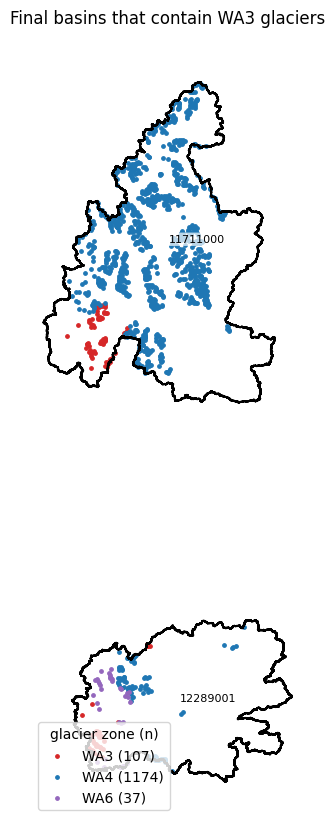

In [35]:
ZC = {'OT3': '#8c564b', 'DA1': '#e377c2', 'DA2': '#7f7f7f', 'DA3': '#bcbd22', 'WA1': '#17becf',
      'WA2': '#2ca02c', 'WA3': '#d62728', 'WA4': '#1f77b4', 'WA5': '#ff7f0e', 'WA6': '#9467bd'}
geom = cm.set_index('gauge_id').geometry.buffer(0)

# final basins (strategy C) that contain WA3 glaciers
wa3_ids = set(gl.index[gl['Cluster'] == 'WA3'])
cover = [u for u in units_C if wa3_ids & set(members.get(u, []))]

rows = []
for u in cover:
    cl = gl.loc[members[u], 'Cluster']
    area_by_zone = gl.loc[members[u]].groupby('Cluster')['Area'].sum()
    rows.append(dict(gauge_id=u, basin_km2=round(geom[u].area / 1e6),
                     zone_by_area=area_by_zone.idxmax(),
                     glaciers_by_zone=cl.value_counts().to_dict()))
print(pd.DataFrame(rows).to_string(index=False))

# map
minx, miny, maxx, maxy = unary_union([geom[u] for u in cover]).bounds
px, py = (maxx - minx) * 0.05, (maxy - miny) * 0.05
fig, ax = plt.subplots(figsize=(7, 10))
for u in cover:
    gpd.GeoSeries([geom[u]], crs=AREA_CRS).boundary.plot(ax=ax, color='k', lw=1.5)
    p = geom[u].representative_point()
    ax.annotate(u, (p.x, p.y), fontsize=8, bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.7))
ids = [g for u in cover for g in members[u]]
for z, d in gl.loc[ids].groupby('Cluster'):
    d.plot(ax=ax, color=ZC[z], markersize=6, label=f'{z} ({len(d)})')
ax.set_xlim(minx - px, maxx + px); ax.set_ylim(miny - py, maxy + py)
ax.legend(title='glacier zone (n)', loc='lower left')
ax.set_axis_off()
ax.set_title('Final basins that contain WA3 glaciers')
plt.show()

In [36]:
print(rgi.groupby('Cluster')['CenLat'].agg(['min', 'median', 'max', 'count']).round(1))

          min  median   max  count
Cluster                           
DA1     -30.5   -27.7 -21.2    422
DA2     -34.1   -33.2 -30.3    200
DA3     -36.4   -34.3 -33.7    410
OT3     -18.4   -18.4 -18.0     34
WA1     -40.2   -38.3 -35.5    678
WA2     -48.2   -43.3 -39.9   2924
WA3     -51.3   -49.0 -46.3    447
WA4     -55.5   -48.1 -44.9   4749
WA5     -50.8   -49.7 -48.1    711
WA6     -55.1   -52.8 -45.9   2671


In [41]:
import os
import pandas as pd

clusters = ['OT3', 'DA1', 'DA2', 'DA3', 'WA1', 'WA2', 'WA3', 'WA4', 'WA5', 'WA6']
datasets = ['CR2MET', 'CRU', 'ERA5']
base_path = '/Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/'
rgi_path  = '/Users/milliespencer/Desktop/CR2_OGGM_Paper/files_chile_OGGM_climate_comparison/RGI_BNA_Clusters.csv'

rgi = pd.read_csv(rgi_path)
rgi['RGIId'] = rgi['RGIId'].astype(str)

rows = []
for dataset in datasets:
    present, valid = set(), set()
    for cluster in clusters:
        f = f'{base_path}{dataset}/{cluster}/mb.csv'
        if not os.path.exists(f):
            print(f'Missing: {dataset}/{cluster}')
            continue
        mb = pd.read_csv(f).set_index('rgi_id')
        present |= set(mb.index.astype(str))
        ok = mb.iloc[:, :20].notna().all(axis=1)
        valid |= set(mb.index[ok].astype(str))
    for label, ids in [('in mb.csv', present), ('in mb.csv with all 20 years', valid)]:
        missing = rgi[~rgi['RGIId'].isin(ids)]
        rows.append({
            'dataset': dataset, 'which': label,
            'simulated': len(ids & set(rgi['RGIId'])),
            'not simulated': len(missing),
            'area not simulated (km2)': round(missing['Area'].sum(), 1),
        })

print(f"RGI total: {len(rgi):,} glaciers, {rgi['Area'].sum():,.1f} km2")
print(pd.DataFrame(rows).to_string(index=False))
print("\nExpected: 86 not simulated, about 459 km2")

RGI total: 13,246 glaciers, 27,499.4 km2
dataset                       which  simulated  not simulated  area not simulated (km2)
 CR2MET                   in mb.csv      13123            123                      68.0
 CR2MET in mb.csv with all 20 years      13123            123                      68.0
    CRU                   in mb.csv      13099            147                      52.5
    CRU in mb.csv with all 20 years      13099            147                      52.5
   ERA5                   in mb.csv      13160             86                      55.9
   ERA5 in mb.csv with all 20 years      13160             86                      55.9

Expected: 86 not simulated, about 459 km2


In [47]:
import os, time
import numpy as np
import pandas as pd
import xarray as xr

clusters = ['OT3', 'DA1', 'DA2', 'DA3', 'WA1', 'WA2', 'WA3', 'WA4', 'WA5', 'WA6']
dataset = 'ERA5'
base_path = '/Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/'
rgi_path  = '/Users/milliespencer/Desktop/CR2_OGGM_Paper/files_chile_OGGM_climate_comparison/RGI_BNA_Clusters.csv'

rgi = pd.read_csv(rgi_path).set_index('RGIId')

by_year = None
rgi_sum = 0
for cluster in clusters:
    t = time.time()
    f = f'{base_path}{dataset}/{cluster}/run_output_2000_2019_hydro_{dataset}_{cluster}.nc'
    if not os.path.exists(f):
        print('Missing:', cluster, flush=True)
        continue
    with xr.open_dataset(f) as ds:
        a = ds['area'].sum('rgi_id').to_series() / 1e6      # km2 per time step
        ids = [str(i) for i in ds['rgi_id'].values]
        times = ds['time'].values
    by_year = a if by_year is None else by_year.add(a, fill_value=0)
    rgi_sum += rgi.loc[[i for i in ids if i in rgi.index], 'Area'].sum()
    print(f'{cluster}: {len(ids)} glaciers, {round(time.time() - t, 1)} s', flush=True)

print('\nERA5 total glacier area by time step (km2):')
print(by_year.round(1).to_string())
print(f'\nRGI area, same glaciers: {rgi_sum:,.1f} km2')

OT3: 34 glaciers, 0.1 s
DA1: 422 glaciers, 0.0 s
DA2: 200 glaciers, 2.7 s
DA3: 410 glaciers, 2.5 s
WA1: 678 glaciers, 2.5 s
WA2: 2924 glaciers, 0.0 s
WA3: 447 glaciers, 0.0 s
WA4: 4749 glaciers, 0.1 s
WA5: 711 glaciers, 3.4 s
WA6: 2671 glaciers, 0.0 s

ERA5 total glacier area by time step (km2):
time
1999.0    27226.8
2000.0    27197.5
2001.0    27242.2
2002.0    27289.3
2003.0    27378.0
2004.0    27378.0
2005.0    27267.2
2006.0    27246.6
2007.0    27236.9
2008.0    27230.4
2009.0    27132.8
2010.0    27191.7
2011.0    27161.3
2012.0    27066.4
2013.0    27028.5
2014.0    26922.3
2015.0    26899.6
2016.0    26809.1
2017.0    26645.4
2018.0    26550.6
2019.0    26469.6
2020.0    26353.1

RGI area, same glaciers: 27,499.4 km2


In [51]:
import os
import pandas as pd

clusters = ['OT3', 'DA1', 'DA2', 'DA3', 'WA1', 'WA2', 'WA3', 'WA4', 'WA5', 'WA6']
datasets = ['CR2MET', 'CRU', 'ERA5']
base_path = '/Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/'

rows = []
for dataset in datasets:
    for cluster in clusters:
        log_dir = f'{base_path}{dataset}/{cluster}/log'
        if not os.path.isdir(log_dir):
            continue
        for fn in os.listdir(log_dir):
            if fn.endswith('.ERROR'):
                rows.append({'dataset': dataset, 'cluster': cluster,
                             'rgi_id': fn.replace('.ERROR', '')})

err = pd.DataFrame(rows)

print('Failed glaciers per dataset (expected CR2MET 123, CRU 147, ERA5 86):')
print(err.groupby('dataset').size().to_string())

print('\nPer cluster and dataset:')
print(err.pivot_table(index='cluster', columns='dataset', values='rgi_id',
                      aggfunc='count', fill_value=0).reindex(clusters))

Failed glaciers per dataset (expected CR2MET 123, CRU 147, ERA5 86):
dataset
CR2MET    123
CRU       851
ERA5       86

Per cluster and dataset:
dataset  CR2MET    CRU  ERA5
cluster                     
OT3         NaN    NaN   NaN
DA1         0.0    1.0   1.0
DA2         NaN    NaN   NaN
DA3         NaN    NaN   NaN
WA1         8.0    7.0   8.0
WA2         9.0   12.0  10.0
WA3         0.0    2.0   0.0
WA4        35.0   48.0  25.0
WA5         4.0  711.0   2.0
WA6        67.0   70.0  40.0


In [52]:
import os
import numpy as np
import xarray as xr

base_path = '/Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/'

# 1. What do the CRU WA5 errors say?
log_dir = f'{base_path}CRU/WA5/log'
ids = [fn for fn in sorted(os.listdir(log_dir)) if fn.endswith('.ERROR')][:3]
for fn in ids:
    with open(os.path.join(log_dir, fn)) as f:
        lines = [l.strip() for l in f.read().splitlines() if l.strip()]
    print(fn)
    for l in lines[-4:]:
        print('    ', l[:160])

# 2. Do these glaciers have melt in the CRU WA5 NetCDF?
nc = xr.open_dataset(f'{base_path}CRU/WA5/run_output_2000_2019_hydro_CRU_WA5.nc')
melt = nc['melt_on_glacier_monthly'].values
has_melt = np.nansum(melt, axis=(0, 1)) > 0
print(f'\nCRU WA5: {len(has_melt)} glaciers in nc, {has_melt.sum()} with melt > 0')

RGI60-17.00570.ERROR
     2026-02-18T18:44:10; init_present_time_glacier; FileNotFoundError; [Errno 2] No such file or directory: '/Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/CRU/
     2026-02-18T18:44:11; run_from_climate_data_2000_2019_hydro_CRU_WA5; InvalidWorkflowError; Need a valid `model_flowlines` file. If you explicitly want to use `in
     2026-02-18T18:44:11; run_with_hydro_2000_2019_hydro_CRU_WA5; InvalidWorkflowError; The run task (run_from_climate_data) did not run successfully.
     2026-02-18T18:45:44; fixed_geometry_mass_balance; FileNotFoundError; [Errno 2] No such file or directory: '/Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/CR
RGI60-17.00571.ERROR
     2026-02-18T18:44:10; init_present_time_glacier; FileNotFoundError; [Errno 2] No such file or directory: '/Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/CRU/
     2026-02-18T18:44:11; run_from_climate_data_2000_2019_hydro_CRU_WA5; InvalidWorkflowError; Need a valid `model_flowlines` file. If you expl